# The quantum metric and the localization of electrons

How far is an electron of an insulator spread in space? In a metal the answer is
infinite, because the states at the Fermi level extend over the whole crystal. In
an insulator it is a finite number, and it is a property of the occupied bands as
a whole. This number is the localization tensor $\langle r_a r_b\rangle_c$, and it
is the zone average of the **quantum metric** of the occupied bands.

Here we compute it for silicon. We get $\langle x^2\rangle_c = 2.58$ bohr$^2$ on a
$12\times12\times12$ mesh. Then we check that the optical absorption gives the same
number, which is what makes it a measured quantity, and we compare diamond,
silicon and AlAs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from defuqumat import Calculator

silicon = dict(lattice='fcc', a=5.43, atoms=[('Si', (0, 0, 0)), ('Si', (0.25, 0.25, 0.25))],
               pseudos={'Si': 'Si.pz-vbc.UPF'}, pseudo_dir='../tests/data/pseudo', ecut=163.3)
si = Calculator.from_keywords(kmesh=(12, 12, 12), **silicon)
metric = si.get_quantum_metric(nbnd=30)
print(np.round(metric.localization_tensor, 4))
print(f'Omega_I = {metric.spread_invariant_angstrom2:.3f} A^2, truncation {metric.truncation:.1e}')

[defuqumat] the quantum metric: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


/u/40/ladovj1/data/Documents/programs/claude/defuqumat/defuqumat/workflows/geometry.py:141: RuntimeWarning: the band set is cut inside a degenerate multiplet: band_cut_gap = 2.80e-14 Ry, below the degeneracy tolerance 1e-05 Ry, the splitting under which two bands are one level. Which members of the multiplet fall below the cut is arbitrary, since any rotation inside it is an equally good set of eigenvectors, so the quantum metric carries a part that is not a property of the crystal: for the metric the rotation moves only the share of the bands at the top of the set, the scale QuantumMetric.truncation reports (1.1e-4 of the tensor on silicon at 30 bands on a 12^3 mesh, where every cut from 20 to 43 bands is inside a multiplet somewhere). Choose an nbnd at which band_cut_gap is a real gap
  return quantum_metric(


[[ 2.5829 -0.      0.    ]
 [-0.      2.5829 -0.    ]
 [-0.     -0.      2.5829]]
Omega_I = 8.680 A^2, truncation 1.1e-04


## What is computed

The occupied Bloch states $|u_{n\mathbf k}\rangle$ change as $\mathbf k$ moves. The
quantum metric says how fast they change:

$$g_{ab}(\mathbf k) = {\rm Re}\sum_{n\,\rm occ}\sum_{m\,\rm empty}
\frac{\langle\psi_n|\partial_{k_a}H|\psi_m\rangle\langle\psi_m|\partial_{k_b}H|\psi_n\rangle}
{(\varepsilon_n-\varepsilon_m)^2}.$$

The imaginary part of the same sum is the Berry curvature. The curvature is zero in
silicon, because the crystal has inversion and time reversal, but the metric is
not. Its average over the zone, per electron, is the localization tensor. For a
cubic crystal it is diagonal, with three equal elements, as we see above. So an
electron of silicon is spread over $\sqrt{2.58} = 1.6$ bohr along each axis. The
trace times the number of Wannier functions is $\Omega_I$, the part of the spread
of Wannier functions that no choice of gauge can lower.

## The optical absorption measures it

Souza, Wilkens and Martin showed that the same tensor is a moment of the optical
conductivity:

$$\langle r_a r_b\rangle_c = \frac{\hbar V}{\pi e^2 N_e}\int_0^\infty \frac{d\omega}{\omega}\,{\rm Re}\,\sigma_{ab}(\omega).$$

So we compute ${\rm Re}\,\sigma_{xx}(\omega)$ of silicon and integrate it. Each
transition is broadened by $\eta$, which adds a small tail, so we take two values
of $\eta$. This needs many frequencies, so we use a $6\times6\times6$ mesh here, and
we compare with the metric on the same mesh.

In [2]:
coarse = Calculator.from_keywords(kmesh=(6, 6, 6), **silicon)
x2 = coarse.get_quantum_metric(nbnd=30).localization_tensor[0, 0]
print(f'<x^2>_c on the 6x6x6 mesh: {x2:.3f} bohr^2')
w = np.linspace(1e-4, 6.0, 15000)                 # Ry
prefactor = float(coarse.system.cell.volume) / (np.pi * 8)
running = {}
for eta in (0.004, 0.002):
    sigma = coarse.get_optical_conductivity(nbnd=30, frequencies=w, broadening=eta, intraband=False)
    integrand = np.real(np.asarray(sigma.interband)[:, 0, 0]) / w
    running[eta] = prefactor * np.concatenate([[0.0], np.cumsum(0.5 * (integrand[1:] + integrand[:-1]) * np.diff(w))])
    print(f'eta = {eta} Ry: integral / metric = {running[eta][-1] / x2:.4f}')
ratios = [running[eta][-1] / x2 for eta in (0.004, 0.002)]
print(f'extrapolated to eta = 0: {2 * ratios[1] - ratios[0]:.4f}')

[defuqumat] the quantum metric: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


/u/40/ladovj1/data/Documents/programs/claude/defuqumat/defuqumat/workflows/geometry.py:141: RuntimeWarning: the band set is cut inside a degenerate multiplet: band_cut_gap = 8.70e-14 Ry, below the degeneracy tolerance 1e-05 Ry, the splitting under which two bands are one level. Which members of the multiplet fall below the cut is arbitrary, since any rotation inside it is an equally good set of eigenvectors, so the quantum metric carries a part that is not a property of the crystal: for the metric the rotation moves only the share of the bands at the top of the set, the scale QuantumMetric.truncation reports (1.1e-4 of the tensor on silicon at 30 bands on a 12^3 mesh, where every cut from 20 to 43 bands is inside a multiplet somewhere). Choose an nbnd at which band_cut_gap is a real gap
  return quantum_metric(


<x^2>_c on the 6x6x6 mesh: 2.980 bohr^2


/u/40/ladovj1/data/Documents/programs/claude/defuqumat/defuqumat/workflows/conductivity.py:197: RuntimeWarning: the band set is cut inside a degenerate multiplet: band_cut_gap = 8.70e-14 Ry, below the degeneracy tolerance 1e-05 Ry, the splitting under which two bands are one level. Which members of the multiplet fall below the cut is arbitrary, since any rotation inside it is an equally good set of eigenvectors, so the optical conductivity sigma_ab carries a part that is not a property of the crystal: on the smeared oxygen atom (o-atom-fixed-lsda.in with a smearing), cut at nbnd = 9 and 8 through a multiplet (band_cut_gap 6e-14 and 3.5e-14 Ry), a random rotation inside each multiplet moves sigma by 5e-4 and 1e-4 of its peak, and at nbnd = 10 (band_cut_gap 7.4e-2 Ry) by nothing. Choose an nbnd at which band_cut_gap is a real gap
  return optical_conductivity(


eta = 0.004 Ry: integral / metric = 1.0691


eta = 0.002 Ry: integral / metric = 1.0346
extrapolated to eta = 0: 1.0001


The integral is a few per cent above the metric, and the excess halves when $\eta$
halves. So it comes from the broadening, and at $\eta \to 0$ the two numbers are
equal. The figure shows where in the spectrum the localization comes from.

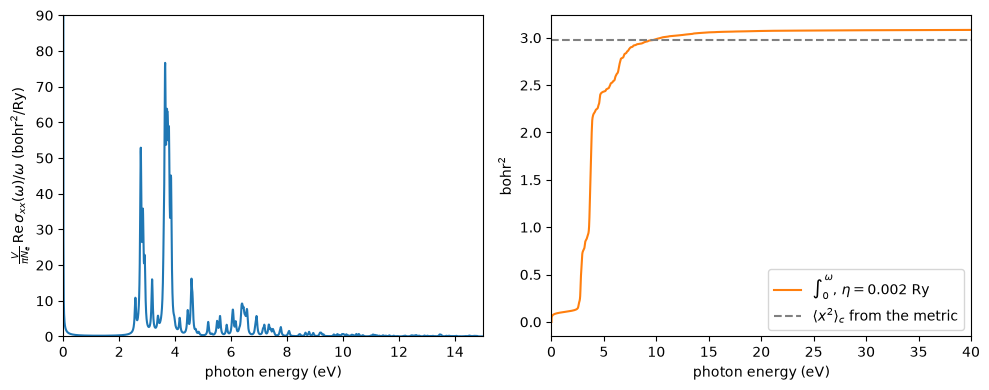

In [3]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
ev = w * 13.6057
left.plot(ev, integrand * prefactor, color='C0')
left.set_xlim(0, 15)
left.set_ylim(0, 90)
left.set_xlabel('photon energy (eV)')
left.set_ylabel(r'$\frac{V}{\pi N_e}\,{\rm Re}\,\sigma_{xx}(\omega)/\omega$ (bohr$^2$/Ry)')
right.plot(ev, running[0.002], color='C1', label=r'$\int_0^\omega$, $\eta = 0.002$ Ry')
right.axhline(x2, color='gray', ls='--', label=r'$\langle x^2\rangle_c$ from the metric')
right.set_xlim(0, 40)
right.set_xlabel('photon energy (eV)')
right.set_ylabel('bohr$^2$')
right.legend()
plt.tight_layout()

On the left is the absorption divided by the frequency. Its two large peaks, at
2.8 and 3.7 eV in this calculation, are the $E_1$ and $E_2$ transitions of
silicon, and the spikes come from the coarse mesh. On the right is the running
integral. It rises steeply between 3 and 5 eV and has about 80% of its value at 5 eV.
It crosses the dashed line at about 10 eV and ends 3.5% above it, which is the
tail of the broadening. So the localization of the electrons is set mostly by
the strong absorption just above the gap. A crystal with a larger gap absorbs at
higher energy, and the $1/\omega$ makes its electrons more localized.

The tensor on the $6\times6\times6$ mesh, 3.0 bohr$^2$, is larger than the 2.58
bohr$^2$ of the $12\times12\times12$ mesh. The metric has a sharp peak at
$\Gamma$, and a coarse mesh gives the $\Gamma$ point too much weight. The
comparison above is on the same mesh, so this does not change it.

## Three crystals

We now compare diamond, silicon and AlAs on the same $12\times12\times12$ mesh. We
also print the smallest direct gap on the path L-$\Gamma$-X.

In [4]:
crystals = {
    'diamond': dict(lattice='fcc', a=3.567, atoms=[('C', (0, 0, 0)), ('C', (0.25, 0.25, 0.25))],
                    pseudos={'C': 'C.pz-rrkjus.UPF'}, ecut=367.4, ecutrho=2939.0),
    'Si': silicon,
    'AlAs': dict(lattice='fcc', a=5.66, atoms=[('Al', (0, 0, 0)), ('As', (0.25, 0.25, 0.25))],
                 pseudos={'Al': 'Al.pz-vbc.UPF', 'As': 'As.pz-bhs.UPF'}, ecut=217.7),
}
print('crystal   <x^2>_c (bohr^2)   Omega_I (A^2)   direct gap (eV)')
for name, keywords in crystals.items():
    keywords = {'pseudo_dir': '../tests/data/pseudo', **keywords}
    calc = Calculator.from_keywords(kmesh=(12, 12, 12), **keywords)
    m = calc.get_quantum_metric(nbnd=30)
    e = np.asarray(calc.get_bands('L-G-X', nbnd=8).eigenvalues_ev)
    print(f'{name:9s} {m.localization_tensor[0, 0]:12.3f} {m.spread_invariant_angstrom2:17.3f} {np.min(e[:, 4] - e[:, 3]):15.2f}')

crystal   <x^2>_c (bohr^2)   Omega_I (A^2)   direct gap (eV)


[defuqumat] the quantum metric: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


diamond          0.847             2.848            5.55


[defuqumat] the quantum metric: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


Si               2.583             8.680            2.58


[defuqumat] the quantum metric: no ground state cached, running the SCF first (conv_thr = 1e-06). Call get_scf() to do this explicitly.


/u/40/ladovj1/data/Documents/programs/claude/defuqumat/defuqumat/workflows/geometry.py:141: RuntimeWarning: the band set is cut inside a degenerate multiplet: band_cut_gap = 4.00e-15 Ry, below the degeneracy tolerance 1e-05 Ry, the splitting under which two bands are one level. Which members of the multiplet fall below the cut is arbitrary, since any rotation inside it is an equally good set of eigenvectors, so the quantum metric carries a part that is not a property of the crystal: for the metric the rotation moves only the share of the bands at the top of the set, the scale QuantumMetric.truncation reports (1.1e-4 of the tensor on silicon at 30 bands on a 12^3 mesh, where every cut from 20 to 43 bands is inside a multiplet somewhere). Choose an nbnd at which band_cut_gap is a real gap
  return quantum_metric(


AlAs             2.416             8.119            2.16


Diamond has the largest gap and the most localized electrons, about three times
less spread than in silicon. AlAs has a smaller direct gap than silicon in this
calculation, but its electrons are a little more localized. The bond of AlAs is
partly ionic, so the valence charge sits closer to the arsenic atom. So the gap
sets the trend and the character of the bond sets the rest. This is the trend
Sgiarovello, Peressi and Resta found for the tetrahedral semiconductors, with
values between 1 and 3 bohr$^2$.

The checks of these numbers are in `tests/unit/test_quantum_metric.py` (a two-band
model with a closed form) and `tests/regression/test_quantum_metric.py` (a second
route from the overlaps of the occupied bands, which needs no empty bands). The
user guide has the theory on its Topology page.